# Visite guidée : exécution optimale et agrégation de liquidité FX

Chaque section suit le même fil : **intuition → formule → attente → code → lecture**.
On écrit ce qu'on s'attend à voir *avant* de lancer le code, puis on compare.

Trois garde-fous à garder en tête tout au long :
- **Pas de volume FX.** Le FX est un marché OTC : la colonne volume des données HistData vaut 0. Le « volume » utilisé ici est un *proxy* d'activité de prix.
- **L'impact de marché est supposé, pas mesuré.** Aucune donnée de transaction : les paramètres sont des hypothèses documentées dans `execfx/impact.py`.
- **TEST (2023+) scellé.** Calibration sur TRAIN (≤ 2018), évaluation sur VAL (2019-2022). Le chargeur refuse toute année ≥ 2023.

Plan : 1. profil intrajournalier · 2. Almgren-Chriss · 3. modèles d'impact · 4. TCA sur jours réels · 5. pas de look-ahead · 6. agrégateur et routeur d'ordres · 7. lecture finale.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from execfx import experiences as ex, almgren_chriss as ac, impact as imp, tca, agregation as ag

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format

## 1. Le profil intrajournalier : à quoi ressemble « le volume » en FX ?

**Intuition.** Un algo d'exécution veut trader quand le marché est liquide (impact faible) et éviter les heures creuses. Il lui faut donc une *courbe de volume* par minute. En FX il n'y a pas de volume centralisé ; on utilise l'activité de prix : plus il y a de transactions, plus le prix bouge de minute en minute (relation volume-volatilité).

**Formule.** Pour la minute $m$ de la journée : $a_m = \mathbb{E}\,|r_m|$ (rendement 1 minute en bps, moyenne sur les jours TRAIN), puis la part du jour $p_m = a_m / \sum_{m'} a_{m'}$ (somme = 1). Le volume simulé de la minute est $V_m = V_{jour}\, p_m\, m_{jour}$.

**Attente.** Des pics nets aux heures rondes et aux événements : annonces US à 8h30, ouverture de la Bourse de New York à 9h30. Les données HistData sont déjà à l'heure locale de New York (été comme hiver, voir le README) : ces pics doivent être *fins* (une seule minute) toute l'année, pas étalés.

TRAIN : 2342 jours ouvrés | VAL utilisables : 1037 / 1043


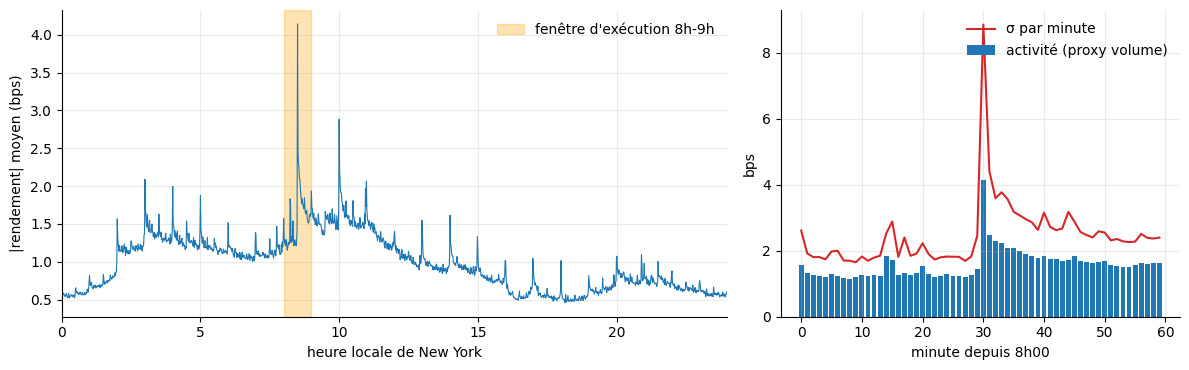

In [2]:
cal = ex.calibrer()
hyp, profil = cal["hyp"], cal["profil"]
print(f"TRAIN : {cal['n_jours_train']} jours ouvrés | VAL utilisables : {len(cal['fenetres_val'])} / {cal['n_jours_val_total']}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1.2]})
a1.plot(np.arange(1440) / 60, profil.activite_bps, lw=0.8)
a1.axvspan(8, 9, color="orange", alpha=0.3, label="fenêtre d'exécution 8h-9h")
a1.set(xlabel="heure locale de New York", ylabel="|rendement| moyen (bps)", xlim=(0, 24)); a1.legend(frameon=False)
d, N = hyp.debut_min, hyp.horizon_min
a2.bar(range(N), profil.activite_bps[d:d + N], label="activité (proxy volume)")
a2.plot(range(N), profil.sigma_min_bps[d:d + N], color="C3", label="σ par minute")
a2.set(xlabel="minute depuis 8h00", ylabel="bps"); a2.legend(frameon=False)
plt.tight_layout(); plt.show()

**Lecture.** Les pics à 8h30 et 10h00 sont d'une seule minute : les données sont bien à l'heure locale de New York été comme hiver (un décalage d'heure d'été appliqué par erreur déplacerait le pic de 8h30 à 9h30 les jours d'été ; `test_fuseau_...` le vérifie). Dans la fenêtre 8h-9h, 8h30 concentre à la fois du volume (barre haute) et beaucoup de risque (σ × 2 à 3) : un VWAP-proxy y placera plus d'ordre, une stratégie sensible au risque s'en méfiera. Rappel : c'est un proxy, pas une mesure de volume.

## 2. Almgren-Chriss : l'arbitrage entre payer l'impact et porter du risque

**Intuition.** Exécuter vite coûte cher en impact (on pousse le prix), exécuter lentement expose au hasard du marché pendant plus longtemps. Il y a un curseur : l'aversion au risque $\lambda$.

**Formules** (ordre parent $X=1$, $N$ tranches d'une minute, $n_k$ = fraction négociée à la tranche $k$, $x_j$ = reste après $j$ tranches) :

$$E = \varepsilon + \sum_k \theta_k n_k^2 + \gamma \sum_k n_k C_{k-1}, \qquad V = \sigma^2 \sum_{j=1}^{N-1} x_j^2$$

On minimise $E + \lambda V$ ; la solution fermée est $x_j = \dfrac{\sinh(\kappa (T - t_j))}{\sinh(\kappa T)}$ avec $\cosh(\kappa\tau) = 1 + \tfrac12 \tilde\kappa^2\tau^2$ et $\tilde\kappa^2 = \lambda\sigma^2/\tilde\eta$.

**Attente.** $\lambda \to 0$ : droite (TWAP). $\lambda$ grand : trajectoire convexe, on vend tôt. La frontière $(\text{risque}, E)$ doit être décroissante et convexe : moins de risque se paie de plus en plus cher.

σ (rms fenêtre, TRAIN) = 2.68 bps/√min | θ moyen = 94.1 bps par fraction d'ordre | participation TWAP nominale = 15%


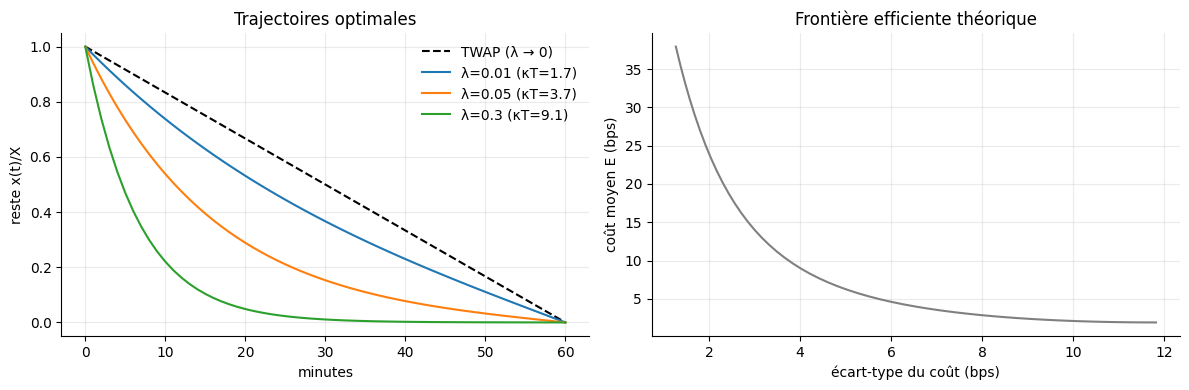

,κT,1re tranche (% ordre),E (bps),écart-type (bps)
λ,,,,
0.010,1.658,2.934,2.213,8.509
0.050,3.708,6.000,3.710,5.697
0.300,9.074,14.036,8.357,3.503


In [3]:
ctx = tca.construire_contexte(profil, hyp, "lineaire")
print(f"σ (rms fenêtre, TRAIN) = {ctx.sigma_ac:.2f} bps/√min | θ moyen = {ctx.theta_ac:.1f} bps par fraction d'ordre | participation TWAP nominale = {hyp.notionnel_eur / (hyp.volume_jour_eur * ctx.part.sum()):.0%}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
t = np.arange(N + 1)
a1.plot(t, 1 - t / N, "k--", label="TWAP (λ → 0)")
lignes = []
for lam in ex.LAMBDAS:
    x = ac.detentions(N, lam, ctx.sigma_ac, ctx.theta_ac, hyp.gamma_bps)
    n = -np.diff(x)
    kT = ac.kappa(lam, ctx.sigma_ac, ctx.theta_ac, hyp.gamma_bps) * N
    a1.plot(t, x, label=f"λ={lam} (κT={kT:.1f})")
    lignes.append({"λ": lam, "κT": kT, "1re tranche (% ordre)": 100 * n[0], "E (bps)": ac.esperance_cout(n, imp.theta_par_tranche(hyp, ctx.part), hyp.gamma_bps, hyp.demi_spread_bps),
                   "écart-type (bps)": np.sqrt(ac.variance_cout(n, ctx.sigma[:-1]))})
a1.set(xlabel="minutes", ylabel="reste x(t)/X", title="Trajectoires optimales"); a1.legend(frameon=False)
front = ex.frontiere_theorique(ctx)
a2.plot(front["std_bps"], front["E_bps"], color="gray")
a2.set(xlabel="écart-type du coût (bps)", ylabel="coût moyen E (bps)", title="Frontière efficiente théorique")
plt.tight_layout(); plt.show()
pd.DataFrame(lignes).set_index("λ")

**Lecture.** Les trajectoires s'incurvent quand $\lambda$ augmente et la frontière est bien décroissante et convexe. Remarque : on prend ici $\sigma$ et $\theta$ constants (hypothèse d'Almgren-Chriss) pour *planifier* ; la théorie « exacte » du tableau utilise les volumes et volatilités par minute du profil.

## 3. Deux modèles d'impact : linéaire et racine carrée

**Intuition.** Plus on prend de part du volume d'une minute, plus on dégrade le prix. Mais de combien ? Les modèles s'opposent sur la forme de la courbe.

**Formules.** Avec $\rho = n X / V_{minute}$ (taux de participation) :
- linéaire : $\text{slippage} = \eta\,\rho$ (c'est le modèle de la théorie d'Almgren-Chriss) ;
- racine carrée : $\text{slippage} = y\,\sigma_{minute}\sqrt{\rho}$ (coût $\propto \sigma\sqrt{q/V}$, appliqué ici **tranche par tranche, à chaque minute**).
Les deux sont **calibrés pour coïncider au TWAP nominal** ; l'impact permanent est linéaire dans les deux. **Attention** : la loi racine carrée de la littérature vaut pour l'**ordre parent entier** (coût $\approx Y\sigma_{jour}\sqrt{Q/V_{jour}}$). Ici l'impact de chaque tranche s'éteint complètement avant la suivante (transitoire à décroissance complète) : c'est un impact temporaire concave, calibré sur le linéaire, donc le linéaire déformé plutôt qu'un second modèle indépendant. Le planning d'Almgren-Chriss reste dérivé sous impact linéaire.

**Attente.** Les courbes se croisent au point de référence. En dessous la racine carrée est *plus chère* (concave : les petites tranches coûtent relativement cher), au-dessus elle est *moins chère*. Donc exécuter agressivement fait moins mal en racine carrée.

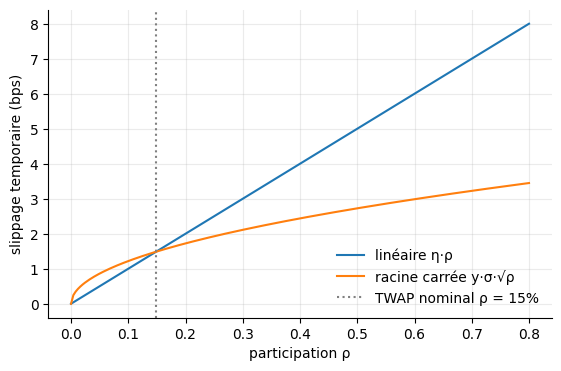

In [4]:
ctx_r = tca.construire_contexte(profil, hyp, "racine")
rho_ref = hyp.notionnel_eur / imp.volume_minute_eur(hyp, ctx.part).sum()
rho = np.linspace(0, 0.8, 200)
plt.figure(figsize=(6.5, 4))
plt.plot(rho, ctx.modele.temporaire_bps(rho, np.mean(ctx.sigma)), label="linéaire η·ρ")
plt.plot(rho, ctx_r.modele.temporaire_bps(rho, np.mean(ctx.sigma)), label="racine carrée y·σ·√ρ")
plt.axvline(rho_ref, color="gray", ls=":", label=f"TWAP nominal ρ = {rho_ref:.0%}")
plt.xlabel("participation ρ"); plt.ylabel("slippage temporaire (bps)"); plt.legend(frameon=False); plt.show()

**Lecture.** Les deux modèles coïncident au point de référence puis divergent. C'est le **risque de modèle** : sans données de fills, on ne sait pas dire lequel est vrai, donc la TCA est rejouée avec les deux (comparaison à la fin de la section 4) et, dans `run_all.py`, avec l'impact × 0,5 et × 2.

## 4. TCA : rejouer des jours réels avec chaque stratégie

**Intuition.** Pour chaque jour VAL on exécute un ordre parent de 50 M EUR dans la fenêtre 8h-9h, en achat **et** en vente, avec 7 stratégies : TWAP, VWAP-proxy, Almgren-Chriss (3 $\lambda$), IS front-loaded (40 % de l'ordre dans les 10 premières minutes) et POV-proxy (suit l'activité observée). Le prix bouge comme le vrai EURUSD ; l'impact est ajouté par le modèle.

**Formule.** Shortfall d'un achat (bps du notionnel, prix d'arrivée = clôture de 7h59) :
$$IS = \underbrace{\sum_k n_k \ln\tfrac{P_k}{P_0}}_{\text{marché (réel)}} + \underbrace{\sum_k n_k\,[\,\text{temp}(\rho_k) + \gamma C_{k-1} + \varepsilon\,]}_{\text{impact (modèle)}}$$
Pour une vente le terme de marché change de signe. Moyennée sur achat + vente, la dérive du prix disparaît : la **moyenne** mesure l'impact, l'**écart-type** mesure le risque de prix réel. IC95 par bootstrap en blocs de 5 jours.

**Attente.** Coût moyen croissant et écart-type décroissant de TWAP vers AC-lam3. L'IS front-loaded (heuristique) doit se trouver *à l'intérieur* de la frontière d'Almgren-Chriss, donc dominé. Le coût empirique doit dépasser la théorie : l'activité du jour fluctue (inégalité de Jensen) et VAL est moins actif que TRAIN.

In [5]:
lin = ex.lancer_tca(cal, "lineaire")
R = lin["resume"]
tab = pd.DataFrame({n: {"shortfall moyen (bps)": v["shortfall_moyen_bps"],
                        "IC95 bas": v["ic95_moyen_bps"][0], "IC95 haut": v["ic95_moyen_bps"][1],
                        "écart-type": v["ecart_type_bps"], "p95": v["p95_bps"],
                        "Δ vs TWAP": v["diff_moyen_vs_twap_bps"],
                        "% exécuté à mi-horizon": 100 * v["part_executee_mi_horizon"]} for n, v in R.items()}).T
print(f"{len(cal['fenetres_val'])} jours VAL x 2 sens = {2 * len(cal['fenetres_val'])} échantillons par stratégie")
tab

1037 jours VAL x 2 sens = 2074 échantillons par stratégie


,shortfall moyen (bps),IC95 bas,IC95 haut,écart-type,p95,Δ vs TWAP,% exécuté à mi-horizon
TWAP,2.590,2.487,2.693,8.262,13.764,0.000,50.000
VWAP-proxy,2.472,2.375,2.570,8.861,14.445,-0.118,41.327
AC-lam1,3.017,2.895,3.140,6.765,12.515,0.428,63.340
AC-lam2,5.161,4.941,5.382,4.806,11.838,2.571,84.710
AC-lam3,11.816,11.291,12.344,5.297,20.536,9.226,98.930
IS-front-loaded,3.850,3.690,4.012,6.434,12.325,1.261,64.000
POV-proxy,2.651,2.566,2.741,7.579,13.489,0.061,51.932


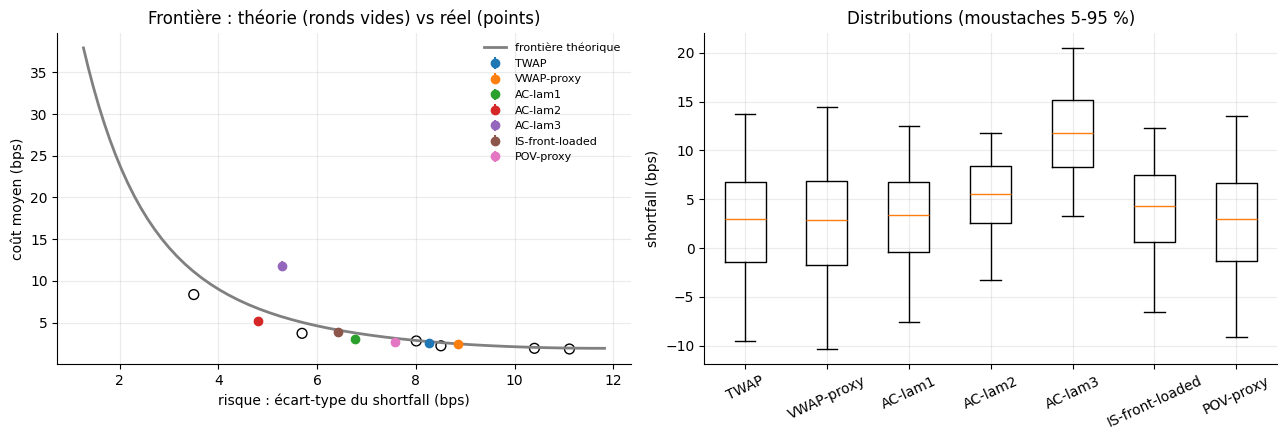

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.plot(front["std_bps"], front["E_bps"], color="gray", lw=2, label="frontière théorique")
for s in lin["strategies"]:
    v = R[s.nom]
    if v["theorie"]:
        a1.scatter(v["theorie"]["std_theorique_bps"], v["theorie"]["E_theorique_bps"], facecolors="none", edgecolors="k", s=50)
    a1.errorbar(v["ecart_type_bps"], v["shortfall_moyen_bps"],
                yerr=[[v["shortfall_moyen_bps"] - v["ic95_moyen_bps"][0]], [v["ic95_moyen_bps"][1] - v["shortfall_moyen_bps"]]], fmt="o", label=s.nom)
a1.set(xlabel="risque : écart-type du shortfall (bps)", ylabel="coût moyen (bps)", title="Frontière : théorie (ronds vides) vs réel (points)")
a1.legend(frameon=False, fontsize=8)
a2.boxplot([lin["res"][n].echantillons().ravel() for n in R], showfliers=False, whis=(5, 95), tick_labels=list(R))
a2.set(ylabel="shortfall (bps)", title="Distributions (moustaches 5-95 %)"); a2.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Lecture.**
- L'arbitrage d'Almgren-Chriss se retrouve sur des trajectoires réelles jusqu'à AC-lam2 : plus $\lambda$ est grand, plus le risque baisse et plus le coût monte. Avec AC-lam3 le risque *remonte* (l'impact varie beaucoup d'un jour à l'autre) tandis que le coût explose.
- Théorie (ronds vides) et réel (points) ne coïncident pas, pour deux raisons mesurables. (1) VAL est moins volatil que TRAIN : le risque de prix des stratégies lentes est surestimé par la théorie (TWAP : point théorique à droite). (2) L'activité du jour fluctue : l'impact moyen est plus élevé que prévu (inégalité de Jensen sur $1/m$) et, pour les stratégies agressives, il varie fortement d'un jour à l'autre, ce qui ajoute du risque absent de la théorie (AC-lam3 : point théorique à gauche). Calibrer sur une période et juger sur une autre expose à ce genre d'écart ; c'est instructif, pas un bug.
- VWAP-proxy et TWAP diffèrent peu en coût (environ -0,12 bp) mais le VWAP-proxy est un peu plus risqué : il charge l'ordre autour du pic de 8h30, où l'impact est plus faible et σ plus fort.
- Aucun planning n'est « le meilleur » : tout dépend de $\lambda$. Le tableau suivant donne le gagnant de l'utilité empirique $E + \lambda\,\mathrm{Var}$ : AC-lam$_i$ est l'optimum *théorique* pour le $i$-ème $\lambda$, et on constate que le gagnant empirique est un cran moins agressif (calibration TRAIN trop prudente pour VAL, régime plus calme et moins liquide).

In [7]:
rac = ex.lancer_tca(cal, "racine")
cmp_ = pd.DataFrame({"coût moyen linéaire": {n: v["shortfall_moyen_bps"] for n, v in R.items()},
                     "coût moyen racine carrée": {n: v["shortfall_moyen_bps"] for n, v in rac["resume"].items()},
                     "écart-type linéaire": {n: v["ecart_type_bps"] for n, v in R.items()},
                     "écart-type racine carrée": {n: v["ecart_type_bps"] for n, v in rac["resume"].items()}})
display(cmp_)
pd.DataFrame({"gagnant (linéaire)": ex.meilleure_par_lambda(R), "gagnant (racine carrée)": ex.meilleure_par_lambda(rac["resume"])})

,coût moyen linéaire,coût moyen racine carrée,écart-type linéaire,écart-type racine carrée
TWAP,2.590,2.056,8.262,8.221
VWAP-proxy,2.472,2.288,8.861,8.829
AC-lam1,3.017,2.054,6.765,6.689
AC-lam2,5.161,2.361,4.806,4.425
AC-lam3,11.816,3.424,5.297,2.739
IS-front-loaded,3.850,2.159,6.434,6.292
POV-proxy,2.651,2.221,7.579,7.541


,gagnant (linéaire),gagnant (racine carrée)
lam=0.01,POV-proxy,AC-lam1
lam=0.05,AC-lam1,AC-lam2
lam=0.3,AC-lam2,AC-lam3


**Lecture (risque de modèle).** Pour les stratégies lentes les écarts-types sont quasi identiques d'un modèle à l'autre (le prix réel les fixe) ; pour les agressives ils baissent en racine carrée car l'impact y varie moins d'un jour à l'autre. Surtout, le coût d'une exécution agressive chute, donc l'urgence optimale change : en racine carrée les gagnants coïncident avec l'optimum théorique AC-lam$_i$, en linéaire hors échantillon ils sont un cran moins agressifs. Le planning Almgren-Chriss étant dérivé sous impact linéaire, il est mal spécifié sous l'impact concave : ces écarts mesurent le risque de modèle, pas une meilleure stratégie.

## 5. Preuve qu'il n'y a pas de look-ahead

**Intuition.** Une simulation d'exécution est facile à tricher sans s'en apercevoir : un algo qui « sait » le prix de la minute suivante bat tout le monde.

**Formule / règle.** À la tranche $k$ (minute 8h00+$k$) la stratégie ne reçoit que `prix[: H+k+1]`, les clôtures jusqu'à la minute précédente.

**Attente.** Si on remplace tous les prix *après* la minute $k_0$ par un autre futur, les quantités décidées jusqu'à $k_0$ doivent être strictement identiques, pour *toutes* les stratégies. Et pour que le test ait du pouvoir, modifier le *passé* doit, lui, changer les décisions de POV.

In [8]:
rng = np.random.default_rng(0)
prix = cal["fenetres_val"][100].copy()
k0 = 25
autre_futur = prix.copy()
autre_futur[ctx.H + k0 + 1:] *= np.exp(np.cumsum(rng.standard_normal(len(prix) - ctx.H - k0 - 1)) * 5e-4)
for s in lin["strategies"]:
    n1, n2 = tca.decider(prix, s, ctx), tca.decider(autre_futur, s, ctx)
    print(f"{s.nom:16s} décisions jusqu'à la minute {k0} identiques : {np.array_equal(n1[:k0 + 1], n2[:k0 + 1])}   (après : {np.array_equal(n1, n2)})")

TWAP             décisions jusqu'à la minute 25 identiques : True   (après : True)
VWAP-proxy       décisions jusqu'à la minute 25 identiques : True   (après : True)
AC-lam1          décisions jusqu'à la minute 25 identiques : True   (après : True)
AC-lam2          décisions jusqu'à la minute 25 identiques : True   (après : True)
AC-lam3          décisions jusqu'à la minute 25 identiques : True   (après : True)
IS-front-loaded  décisions jusqu'à la minute 25 identiques : True   (après : True)
POV-proxy        décisions jusqu'à la minute 25 identiques : True   (après : False)


**Lecture.** Les décisions jusqu'à $k_0$ sont identiques partout. Après $k_0$, seules les stratégies adaptatives (POV-proxy) peuvent différer, ce qui est normal : elles ont vu un autre passé. La même vérification tourne en continu dans `tests/test_tca.py`.

## 6. Agrégateur de liquidité : le meilleur prix affiché n'est pas la meilleure exécution

**Intuition.** Un client envoie un ordre à un agrégateur qui voit les cotes de 8 fournisseurs (LP). Le plus tentant : aller chez celui qui affiche le meilleur prix. Problème : beaucoup de LP serrés appliquent un **last look**. Après réception de l'ordre, ils regardent le marché quelques dizaines de ms et rejettent si le prix a bougé contre eux. Et leurs cotes sont un peu **périmées** (latence). Le meilleur prix affiché est donc, par construction, la cote la plus susceptible d'être périmée donc rejetée. Un rejet force à re-router dans un marché qui a déjà bougé.

**Formules.** Coût vu du client en pips : $c = s\,(P_{payé} - P_{mid,0})$. Cote du LP $i$ : $c_i = s\,(M_{t - \ell_i} - M_0) + h_i + \nu_i z$ ($\ell_i$ latence, $h_i$ demi-spread, $\nu_i$ bruit). Rejet si le marché a bougé de plus de $x_i$ pip contre le LP **et** un tirage de probabilité $p_i = p^{base}_i + \text{pente}_i \cdot \text{toxicité}$.
Routeurs : (a) tri par $c_i$ ; (b) tri par coût attendu $c_i + \hat p_i \times (\text{coût de re-routage})$ avec $\hat p_i$ et le surcoût de re-routage **appris sur TRAIN** ; (c) split en 3 parts égales sur les 3 meilleurs de (b). Les trois routeurs rejouent exactement les mêmes aléas (nombres aléatoires communs).

**Attente.** (1) Le prix obtenu est plus mauvais que le meilleur prix affiché, et l'écart augmente avec la toxicité. (2) (b) rejette moins et va plus vite que (a). (3) Les gains de (b) sur le coût moyen sont petits (ordre de grandeur : le centième de pip) parce qu'un LP serré reste attractif même après pénalité.

In [9]:
agg = ex.lancer_agregation(cal)   # mêmes tailles et mêmes graines que run_all.py : 10 000 ordres TRAIN, 20 000 ordres VAL par niveau de toxicité
lignes = []
for tox, res in agg["resultats"].items():
    for r in ag.ROUTEURS:
        o = res[r]
        lignes.append({"toxicité": tox.split("=")[1], "routeur": r, "meilleur affiché (pip)": o["meilleur_affiche_pips"],
                       "prix effectif (pip)": o["prix_effectif_pips"]["moyenne"],
                       "IC95 bas": o["prix_effectif_pips"]["ic95"][0], "IC95 haut": o["prix_effectif_pips"]["ic95"][1],
                       "rejets/ordre": o["rejets_par_ordre"], "ordres avec rejet": o["ordres_avec_rejet"],
                       "remplissage": o["taux_remplissage"], "délai (ms)": o["delai_dernier_fill_ms"]})
pd.DataFrame(lignes).set_index(["toxicité", "routeur"])

meilleur affiché (pip)  prix effectif (pip)  \
toxicité routeur                                                           
0.1      a_meilleur_affiche                  -0.014                0.023   
         b_prix_effectif                     -0.014                0.023   
         c_split                             -0.014                0.025   
0.5      a_meilleur_affiche                  -0.014                0.035   
         b_prix_effectif                     -0.014                0.035   
         c_split                             -0.014                0.037   
0.9      a_meilleur_affiche                  -0.014                0.049   
         b_prix_effectif                     -0.014                0.049   
         c_split                             -0.014                0.051   

                             IC95 bas  IC95 haut  rejets/ordre  \
toxicité routeur                                                 
0.1      a_meilleur_affiche     0.022      0.024         0.184   
         b_prix_effectif        0.022      0.024         0.182   
         c_split                0.024      0.026         0.183   
0.5      a_meilleur_affiche     0.034      0.036         0.476   
         b_prix_effectif        0.034      0.036         0.454   
         c_split                0.036      0.038         0.458   
0.9      a_meilleur_affiche     0.049      0.050         0.785   
         b_prix_effectif        0.048      0.050         0.705   
         c_split                0.050      0.052         0.717   

                             ordres avec rejet  remplissage  délai (ms)  
toxicité routeur                                                         
0.1      a_meilleur_affiche              0.154        1.000     198.093  
         b_prix_effectif                 0.153        1.000     195.373  
         c_split                         0.153        1.000     196.543  
0.5      a_meilleur_affiche              0.313        0.999     215.411  
         b_prix_effectif                 0.302        0.999     204.704  
         c_split                         0.303        0.999     206.710  
0.9      a_meilleur_affiche              0.407        0.998     229.814  
         b_prix_effectif                 0.378        0.998     201.703  
         c_split                         0.380        0.998     206.309

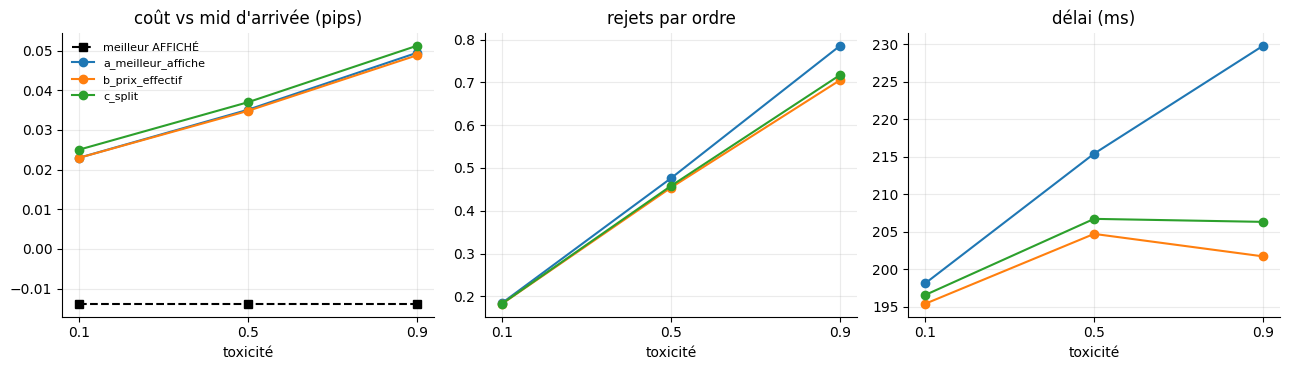

,part d'ordres où (a) et (b) choisissent un LP différent,coût (a) - coût (b) sur ces ordres (pip),IC95 bas,IC95 haut
toxicite=0.1,0.0285,-0.0003,-0.0012,0.0006
toxicite=0.5,0.1017,0.0011,0.0000,0.0021
toxicite=0.9,0.1986,0.0013,0.0005,0.0021


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
tox = list(agg["resultats"]); x = [float(k.split("=")[1]) for k in tox]
ax[0].plot(x, [agg["resultats"][k]["a_meilleur_affiche"]["meilleur_affiche_pips"] for k in tox], "k--s", label="meilleur AFFICHÉ")
for r in ag.ROUTEURS:
    for a, cle, sous in zip(ax, ["prix_effectif_pips", "rejets_par_ordre", "delai_dernier_fill_ms"], [True, False, False]):
        a.plot(x, [agg["resultats"][k][r][cle]["moyenne"] if sous else agg["resultats"][k][r][cle] for k in tox], "o-", label=r)
for a, t in zip(ax, ["coût vs mid d'arrivée (pips)", "rejets par ordre", "délai (ms)"]):
    a.set(xlabel="toxicité", title=t); a.set_xticks(x)
ax[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
dz = {k: v["desaccord_a_vs_b"] for k, v in agg["resultats"].items()}
tab = pd.DataFrame({k: {"part d'ordres où (a) et (b) choisissent un LP différent": d["part_ordres"],
                        "coût (a) - coût (b) sur ces ordres (pip)": d["cout_a_moins_cout_b_pips"]["moyenne"],
                        "IC95 bas": d["cout_a_moins_cout_b_pips"]["ic95"][0], "IC95 haut": d["cout_a_moins_cout_b_pips"]["ic95"][1]}
                    for k, d in dz.items()}).T
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab)

**Lecture.**
- Le « meilleur prix affiché » est même *meilleur que le mid* (cote périmée ou bruitée) mais n'est jamais obtenu : le prix effectif est plus cher, de plus en plus quand la toxicité monte. Le prix affiché est une cible inatteignable, pas un prix d'exécution.
- Le routeur (b) rejette moins et exécute plus vite que (a), surtout à forte toxicité. Son gain de coût moyen est minuscule : il se concentre sur les ordres où (a) et (b) divergent (3 % à 20 % des ordres), de l'ordre du millième de pip, et son IC95 ne s'écarte nettement de zéro qu'à forte toxicité (à toxicité moyenne sa borne basse touche zéro). À faible toxicité on ne détecte rien. Honnêtement : le gain principal du routage ajusté du risque est la fiabilité (moins de rejets, moins de délai), pas le prix moyen.
- Le split (c) coûte un peu plus cher en moyenne ici : le modèle ne valorise pas ce que le split apporte réellement (moins de fuite d'information, plus de profondeur).
- Limite importante : les paramètres des 8 LP sont **inventés** (stylisés). Les conclusions qualitatives (écart affiché/obtenu, rejets, délais) découlent de la mécanique ; les niveaux en pips ne sont pas ceux d'un vrai agrégateur.

## 7. Lecture finale et ce que le projet démontre

Le fichier `results/verdict_execution.json` (produit par `scripts/run_all.py`, plus gros échantillons) contient la lecture complète : ci-dessous ses phrases-clés, générées à partir des chiffres.

- **Algos d'exécution** : TWAP, VWAP, IS et POV sont les briques classiques ; Almgren-Chriss fournit le cadre pour choisir l'urgence ; le simulateur de coûts sert à les comparer honnêtement (l'impact reste supposé).
- **Smart order routing** : un agrégateur qui voit de nombreux fournisseurs de liquidité pose exactement la question de la section 6 : classer par prix affiché ou par prix effectif ajusté du risque de rejet (ici 8 fournisseurs fictifs).
- **Best execution** : mesurer l'implementation shortfall contre le prix d'arrivée, avec incertitude (bootstrap), sans look-ahead, et en séparant ce qui vient du marché de ce qui vient du modèle d'impact.

In [11]:
v = json.load(open("../results/verdict_execution.json", encoding="utf-8"))
for ligne in v["lecture"]:
    print("-", ligne, "\n")
print("LIMITES :"); [print(" *", l) for l in v["limites"]];

- Impact linéaire : coût moyen le plus bas = VWAP-proxy (2.47 bps), risque le plus bas = AC-lam2 (écart-type 4.81 bps, mais coût 5.16 bps) : on paie la réduction de risque en impact. 

- VWAP-proxy vs TWAP : écart de coût moyen -0.118 bps, IC95 [-0.123, -0.112] (bootstrap par blocs de 5 jours, apparié) : statistiquement non nul, mais économiquement faible (1.4 % de l'écart-type du shortfall du TWAP). 

- Frontière : de AC-lam1 à AC-lam3 le coût moyen passe de 3.02 à 11.82 bps et l'écart-type de 6.76 à 5.30 bps : l'arbitrage coût/risque d'Almgren-Chriss se retrouve sur données réelles. 

- Hors échantillon (TRAIN -> VAL) : σ rms de la fenêtre 2.18 bps/min en VAL contre 2.68 en TRAIN, activité du jour m moyen 0.84 (médiane 0.72) : la théorie calibrée sur TRAIN surestime le risque (TWAP : écart-type théorique 10.4 vs 8.3 empirique) et sous-estime l'impact (TWAP : 1.91 vs 2.59 bps). 

- Pourquoi la théorie ne tombe pas pile : pour AC-lam3 l'écart-type du shortfall (5.30 bps) mêle le risque